In [32]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense
from tensorflow.keras.utils import to_categorical

In [33]:
# Load dataset

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (60000, 28, 28)
Testing Data Shape: (10000, 28, 28)


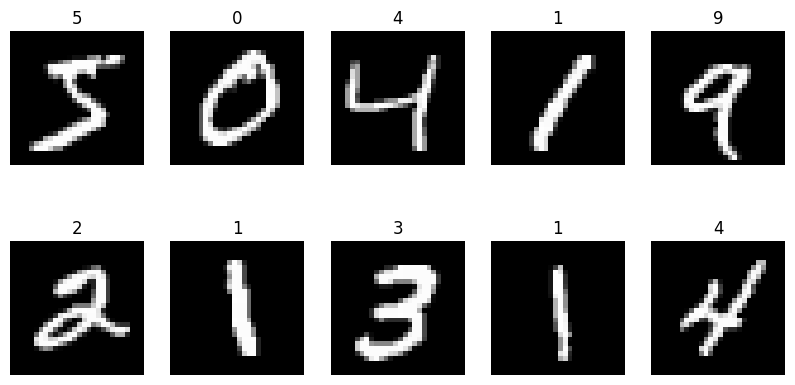

In [34]:
plt.figure(figsize=(10,5))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(y_train[i])
    plt.axis('off')

plt.show()

In [35]:
# Normalize pixel values

X_train = X_train / 255.0
X_test = X_test / 255.0

# Reshape for CNN

X_train = X_train.reshape(60000,28,28,1)
X_test = X_test.reshape(10000,28,28,1)

# One-hot encoding

y_train = to_categorical(y_train,10)
y_test = to_categorical(y_test,10)

print("Preprocessing Completed")

Preprocessing Completed


In [36]:
model = Sequential()

model.add(
    Conv2D(
        32,
        (3,3),
        activation='relu',
        input_shape=(28,28,1)
    )
)

model.add(MaxPooling2D(pool_size=(2,2)))

model.add(
    Conv2D(
        64,
        (3,3),
        activation='relu'
    )
)

model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Flatten())

model.add(Dense(128, activation='relu'))

model.add(Dense(10, activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [37]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [38]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.9477 - loss: 0.1743 - val_accuracy: 0.9847 - val_loss: 0.0546
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9831 - loss: 0.0526 - val_accuracy: 0.9885 - val_loss: 0.0386
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9883 - loss: 0.0364 - val_accuracy: 0.9887 - val_loss: 0.0392
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9917 - loss: 0.0264 - val_accuracy: 0.9882 - val_loss: 0.0362
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9931 - loss: 0.0208 - val_accuracy: 0.9903 - val_loss: 0.0419


In [39]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9899 - loss: 0.0308
Test Loss: 0.030772704631090164
Test Accuracy: 0.9898999929428101


In [40]:
predictions = model.predict(X_test)

predicted_labels = np.argmax(predictions, axis=1)
actual_labels = np.argmax(y_test, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


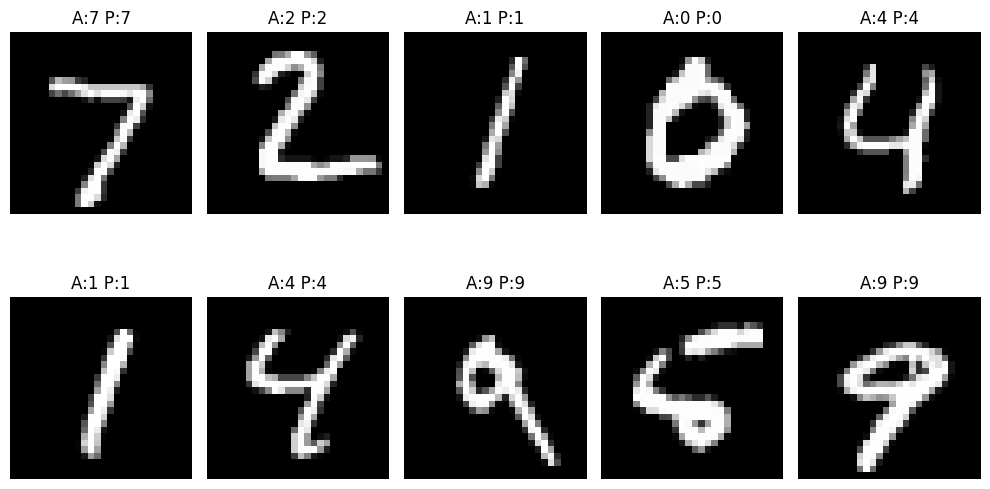

In [41]:
plt.figure(figsize=(10,6))

for i in range(10):

    plt.subplot(2,5,i+1)

    plt.imshow(X_test[i].reshape(28,28), cmap='gray')

    plt.title(
        f"A:{actual_labels[i]} P:{predicted_labels[i]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [42]:
import streamlit as st
st.title("Student Marks Calculator")

2026-11-21 15:02:38.219 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 15:02:38.220 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 15:02:38.221 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


DeltaGenerator()

In [43]:
!pip install -q streamlit
import streamlit as st

st.title("Student Marks Calculator")

st.write("Enter marks of 5 subjects")

m1 = st.number_input("Subject 1", 0, 100)
m2 = st.number_input("Subject 2", 0, 100)
m3 = st.number_input("Subject 3", 0, 100)
m4 = st.number_input("Subject 4", 0, 100)
m5 = st.number_input("Subject 5", 0, 100)

if st.button("Calculate"):

    total = m1 + m2 + m3 + m4 + m5

    percentage = total / 5

    if percentage >= 90:
        grade = "A+"
    elif percentage >= 80:
        grade = "A"
    elif percentage >= 70:
        grade = "B"
    elif percentage >= 60:
        grade = "C"
    elif percentage >= 50:
        grade = "D"
    else:
        grade = "F"

    st.success("Calculation Completed")

    st.write("Total Marks:", total)
    st.write("Percentage:", percentage)
    st.write("Grade:", grade)

2026-11-21 15:02:41.753 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 15:02:41.754 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 15:02:41.755 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 15:02:41.757 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 15:02:41.757 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 15:02:41.758 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 15:02:41.759 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 15:02:41.760 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

In [44]:
%%writefile app.py

import streamlit as st

st.title("Student Marks Calculator")

st.write("Enter marks of 5 subjects")

m1 = st.number_input("Subject 1", 0, 100)
m2 = st.number_input("Subject 2", 0, 100)
m3 = st.number_input("Subject 3", 0, 100)
m4 = st.number_input("Subject 4", 0, 100)
m5 = st.number_input("Subject 5", 0, 100)

if st.button("Calculate"):
    total = m1 + m2 + m3 + m4 + m5
    percentage = total / 5

    if percentage >= 90:
        grade = "A+"
    elif percentage >= 80:
        grade = "A"
    elif percentage >= 70:
        grade = "B"
    elif percentage >= 60:
        grade = "C"
    elif percentage >= 50:
        grade = "D"
    else:
        grade = "F"

    st.success("Calculation Completed")
    st.write("Total Marks:", total)
    st.write("Percentage:", percentage)
    st.write("Grade:", grade)

Overwriting app.py


In [45]:
!ls

app.py	sample_data


In [ ]:
!streamlit run app.py



2026-11-21 15:02:45.143 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.240.144.175:8501

